In [1]:
%%writefile q2_core.py
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.cluster import KMeans

class Normalizer:
    """Per-condition scaling. k = 1 gives one overall mean/spread (condition ignored)."""
    def __init__(self, k): self.k = k
    def _regime(self, df):
        if self.k == 1: return np.zeros(len(df), int)
        S = (df[self.settings].values - self.s_mu) / self.s_sd
        return ((S[:, None, :] - self.centers[None]) ** 2).sum(2).argmin(1)
    def fit(self, df, sensors, settings, seed=42):
        self.sensors, self.settings = list(sensors), list(settings)
        if self.k > 1:
            S = df[self.settings].values; self.s_mu, self.s_sd = S.mean(0), S.std(0) + 1e-9
            self.centers = KMeans(self.k, n_init=10, random_state=seed).fit((S - self.s_mu) / self.s_sd).cluster_centers_
        reg, X = self._regime(df), df[self.sensors].values
        gm, gs = X.mean(0), X.std(0) + 1e-9
        self.mu, self.sd = np.zeros((self.k, len(sensors))), np.ones((self.k, len(sensors)))
        for r in range(self.k):
            m = reg == r
            if m.sum() > 10:
                self.mu[r] = X[m].mean(0); s = X[m].std(0); self.sd[r] = np.where(s < 1e-9, 1.0, s)
            else:
                self.mu[r], self.sd[r] = gm, gs
        return self
    def transform(self, df):
        reg = self._regime(df)
        return (df[self.sensors].values - self.mu[reg]) / self.sd[reg]
    def state(self):
        return dict(k=self.k, mu=self.mu, sd=self.sd, sensors=self.sensors, settings=self.settings,
                    s_mu=getattr(self, "s_mu", None), s_sd=getattr(self, "s_sd", None), centers=getattr(self, "centers", None))
    @classmethod
    def from_state(cls, st):
        n = cls(st["k"]); n.__dict__.update({k: v for k, v in st.items() if k != "k"}); return n

def rebuild_path(Wd):
    # Wd: scaled one-step changes inside a window, shape (m, S, L-1). Returns a path of length L that starts at 0.
    return np.concatenate([np.zeros_like(Wd[:, :, :1]), np.cumsum(Wd, axis=2)], axis=2)

def feats_C(Wl, Wt):
    # Wl: window levels -> mean/std/min/max/median.  Wt: window used for slope and change features.  Both (m, S, L).
    L = Wl.shape[2]; t = np.arange(L) - (L - 1) / 2
    dW = np.diff(Wt, axis=2)
    return np.concatenate([Wl.mean(2), Wl.std(2), Wl.min(2), Wl.max(2), np.median(Wl, 2),
                           (Wt * t).sum(2) / (t ** 2).sum(), Wt[:, :, -1] - Wt[:, :, 0], dW.std(2), np.abs(dW).mean(2)], axis=1)

def raw_diffs(df, sensors):
    X = df[list(sensors)].values; dX = np.zeros_like(X); dX[1:] = X[1:] - X[:-1]
    first = np.r_[True, df["unit_id"].values[1:] != df["unit_id"].values[:-1]]; dX[first] = 0      # no change across engines
    return dX

def arm_inputs(arm, df, sensors, norm1, normk):
    """returns (levels, scaled raw changes or None, extra columns or None)"""
    if arm == "N":  return norm1.transform(df), None, None
    if arm == "R":  return norm1.transform(df), None, np.eye(normk.k)[normk._regime(df)]
    if arm == "AF": return normk.transform(df), None, None
    if arm == "DF": return normk.transform(df), raw_diffs(df, sensors) / normk.sd[normk._regime(df)], None
    raise ValueError(arm)

def build(Xlev, Xdiff, extra, groups, units, L, start, stride):
    """one feature row per window ending at cycle t (t >= max(L, start)); only cycles up to t are used."""
    feats, rows = [], []
    for u in units:
        idx = groups[u]; n = len(idx)
        ends = np.arange(max(L, start) - 1, n, stride)
        if len(ends) == 0: continue
        sel = ends - (L - 1)
        Wl = sliding_window_view(Xlev[idx], L, axis=0)[sel]
        Wt = Wl if Xdiff is None else rebuild_path(sliding_window_view(Xdiff[idx], L, axis=0)[sel][:, :, 1:])
        f = feats_C(Wl, Wt)
        if extra is not None: f = np.hstack([f, extra[idx[ends]]])
        feats.append(f); rows.append(idx[ends])
    return np.vstack(feats), np.concatenate(rows)

def last_window_features(Xlev, Xdiff, extra, groups, units, L):
    """one row per engine: the last L cycles. Short engines are padded by repeating the first reading (changes padded with 0)."""
    out = []
    for u in units:
        idx = groups[u]; a = Xlev[idx]
        if len(a) < L: a = np.vstack([np.repeat(a[:1], L - len(a), 0), a])
        Wl = a[-L:].T[None]
        if Xdiff is None: Wt = Wl
        else:
            d = Xdiff[idx]
            if len(d) < L: d = np.vstack([np.zeros((L - len(d), d.shape[1])), d])
            Wt = rebuild_path(d[-L:].T[None][:, :, 1:])
        f = feats_C(Wl, Wt)
        if extra is not None: f = np.hstack([f, extra[idx[-1]][None]])
        out.append(f[0])
    return np.array(out)

def nasa_terms(y, p):
    d = p - y
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)

def predict_from_bundle(bundle, df, rul_cap=125):
    """df: raw readings (unit_id, cycle, settings, sensors) of one or more engines. Returns {unit_id: predicted RUL}."""
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    n1, nk = Normalizer.from_state(bundle["norm1"]), Normalizer.from_state(bundle["normk"])
    lev, dif, ex = arm_inputs(bundle["arm"], df, bundle["sensors"], n1, nk)
    groups = df.groupby("unit_id").indices; units = sorted(groups)
    p = np.clip(bundle["model"].predict(last_window_features(lev, dif, ex, groups, units, bundle["L"])), 0, rul_cap)
    return dict(zip(units, p))

Writing q2_core.py


## 1. Settings

In [2]:
import os, time, shutil, warnings, subprocess, importlib.util
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
import q2_core as qc
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

QUICK = os.environ.get("CMAPSS_QUICK", "0") == "1"      # QUICK=1 runs a small, fast version to test the notebook
DATA_DIR = os.environ.get("CMAPSS_DIR", "/kaggle/input/datasets/tanmoypauldiat/cmapps-fd001-and-fd002")
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs_q2"
MODEL_DIR = f"{OUT_DIR}/q2_models"; os.makedirs(MODEL_DIR, exist_ok=True)

SEED = 42                  # same seed as the Q1 notebook
DATASETS = ["FD001", "FD002"]
MODELS = ["RF", "XGB", "ADA"]
L = 50                     # fixed window length
N_FOLDS = 5
RUL_CAP = 125
MIN_EVAL_CYCLE = 50        # validation rows: all cycles >= 50 of the held-out engines
EARLY_RUL, NEAR_RUL = 100, 30
TRAIN_STRIDE = 4           # every 4th training window (windows overlap heavily), as in Q1
N_BOOT = 2000              # engine-level bootstrap repeats for the hypothesis tests
REPEATS = 1                # a single 5-fold split, as in Q1
if QUICK: TRAIN_STRIDE = 8; N_BOOT = 300

USE_TORCH = importlib.util.find_spec("torch") is not None
EXT = ".pth" if USE_TORCH else ".pkl"
def save_obj(obj, path):
    if USE_TORCH:
        import torch; torch.save(obj, path)
    else:
        import joblib; joblib.dump(obj, path)
def load_obj(path):
    if path.endswith(".pth"):
        import torch; return torch.load(path, weights_only=False)
    import joblib; return joblib.load(path)

def gpu_available():
    try: return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except Exception: return False
USE_GPU = gpu_available()

def make_folds(units, seed=SEED):                      # identical to the Q1 notebook
    u = np.array(sorted(units)); rng = np.random.default_rng(seed); rng.shuffle(u)
    return {int(e): i % N_FOLDS for i, e in enumerate(u)}
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))
print("QUICK =", QUICK, "| seed", SEED, "| L =", L, "| GPU:", USE_GPU, "| model files:", EXT, "| data:", DATA_DIR)

QUICK = False | seed 42 | L = 50 | GPU: False | model files: .pth | data: /kaggle/input/datasets/tanmoypauldiat/cmapps-fd001-and-fd002


## 2. Load data

In [3]:
def add_rul(df):
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    df["RUL"] = df.groupby("unit_id")["cycle"].transform("max") - df["cycle"]
    df["y"] = df["RUL"].clip(upper=RUL_CAP); return df

def read_rul(path, n_expected):
    r = pd.read_csv(path, header=None).apply(pd.to_numeric, errors="coerce").dropna()
    v = r.iloc[:, 0].values
    if len(v) == n_expected + 1: v = v[1:]
    return v

DATA = {}
for ds in DATASETS:
    tr = add_rul(pd.read_csv(f"{DATA_DIR}/train_{ds}.csv"))
    te = pd.read_csv(f"{DATA_DIR}/test_{ds}.csv").sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    rul = read_rul(f"{DATA_DIR}/RUL_{ds}.csv", te["unit_id"].nunique()); assert len(rul) == te["unit_id"].nunique()
    sensors = [c for c in tr.columns if c.startswith("sensor") and tr[c].std() > 0]                 # same rule as Q1
    settings = [c for c in tr.columns if c not in ("unit_id", "cycle", "RUL", "y") and not c.startswith("sensor")]
    DATA[ds] = dict(train=tr, test=te, y_test=np.minimum(rul, RUL_CAP).astype(float), sensors=sensors, settings=settings,
                    n_regimes=6 if ds == "FD002" else 1, groups=tr.groupby("unit_id").indices, tegroups=te.groupby("unit_id").indices)
display(pd.DataFrame([dict(dataset=ds, train_engines=len(d["groups"]), train_rows=len(d["train"]), test_engines=len(d["tegroups"]),
                           test_engines_shorter_than_L=int(sum(len(v) < L for v in d["tegroups"].values())),
                           sensors=len(d["sensors"]), regimes=d["n_regimes"]) for ds, d in DATA.items()]))

,dataset,train_engines,train_rows,test_engines,test_engines_shorter_than_L,sensors,regimes
0,FD001,100,20631,100,7,19,1
1,FD002,260,53759,259,24,21,6


## 3. Checks on the pieces (all must print OK)

In [4]:
def norms(d, df):
    return (qc.Normalizer(1).fit(df, d["sensors"], d["settings"], SEED),
            qc.Normalizer(d["n_regimes"]).fit(df, d["sensors"], d["settings"], SEED))

d1, d2 = DATA["FD001"], DATA["FD002"]
# 1) FD001: one condition, so N, AF and DF give identical features
n1, nk = norms(d1, d1["train"]); u = list(d1["groups"])[:6]; F = {}
for arm in ["N", "AF", "DF"]:
    lev, dif, ex = qc.arm_inputs(arm, d1["train"], d1["sensors"], n1, nk); F[arm] = qc.build(lev, dif, ex, d1["groups"], u, L, 50, 3)[0]
assert np.allclose(F["N"], F["AF"], atol=1e-9) and np.allclose(F["AF"], F["DF"], atol=1e-7)
print("OK  FD001: N, AF and DF features are identical (one condition)")

# 2) FD002: the three conditions differ
n1, nk = norms(d2, d2["train"]); u = list(d2["groups"])[:6]; G = d2["groups"]; df2 = d2["train"]; F = {}
for arm in ["N", "AF", "DF"]:
    lev, dif, ex = qc.arm_inputs(arm, df2, d2["sensors"], n1, nk); F[arm] = qc.build(lev, dif, ex, G, u, L, 60, 3)[0]
assert not np.allclose(F["N"], F["AF"]) and not np.allclose(F["AF"], F["DF"]) and F["N"].shape == F["DF"].shape
print("OK  FD002: N, AF and DF features differ; feature count per row:", F["N"].shape[1])

# 3) no future leakage: destroy every reading after cycle t; features at t must not change
idx = G[u[0]]; t = min(100, len(idx) - 1)
for arm in ["N", "AF", "DF"]:
    lev, dif, ex = qc.arm_inputs(arm, df2, d2["sensors"], n1, nk)
    f1, r1 = qc.build(lev, dif, ex, G, [u[0]], L, t, 10**6)
    lev2 = lev.copy(); lev2[idx[t:]] = 1e6; dif2 = None if dif is None else dif.copy()
    if dif2 is not None: dif2[idx[t:]] = 1e6
    f2, _ = qc.build(lev2, dif2, None, G, [u[0]], L, t, 10**6)
    assert len(r1) == 1 and df2.loc[r1[0], "cycle"] == t and np.allclose(f1, f2)
print("OK  every condition: the window ends at cycle t and ignores later cycles")

# 4) DF by hand: last-minus-first of the rebuilt path = sum of the scaled raw changes in the window
lev, dif, ex = qc.arm_inputs("DF", df2, d2["sensors"], n1, nk); f, r = qc.build(lev, dif, ex, G, [u[0]], L, t, 10**6)
S_ = len(d2["sensors"]); assert np.allclose(f[0, 6 * S_:7 * S_], dif[idx[t - L + 1:t]].sum(0))
print("OK  DF: last-minus-first equals the sum of the scaled raw changes")

# 5) the test-time (last window) features equal the training-time features for the same cycle
for arm in ["N", "AF", "DF"]:
    lev, dif, ex = qc.arm_inputs(arm, df2, d2["sensors"], n1, nk); n_u = len(idx)
    fa, _ = qc.build(lev, dif, ex, G, [u[0]], L, n_u, 10**6); fb = qc.last_window_features(lev, dif, ex, G, [u[0]], L)
    assert np.allclose(fa, fb)
print("OK  last-window features (used on the test set) match the training features")

# 6) padding: engines shorter than L still give finite features, in all three conditions
for ds, d in DATA.items():
    n1, nk = norms(d, d["train"]); short = [uu for uu, v in d["tegroups"].items() if len(v) < L]
    for arm in ["N", "AF", "DF"]:
        lev, dif, ex = qc.arm_inputs(arm, d["test"], d["sensors"], n1, nk)
        if short:
            f = qc.last_window_features(lev, dif, ex, d["tegroups"], short, L); assert np.isfinite(f).all()
    print(f"OK  {ds}: {len(short)} short test engines padded without problems")

# 8) the folds cover every engine exactly once (same function and seed as Q1)
for ds, d in DATA.items():
    fo = make_folds(list(d["groups"]), SEED); cnt = np.bincount(list(fo.values()), minlength=N_FOLDS)
    assert len(fo) == len(d["groups"]) and set(fo.values()) == set(range(N_FOLDS)) and cnt.max() - cnt.min() <= 1
    print(f"OK  {ds}: 5 folds, engines per fold {cnt.tolist()}")

# 7) slope formula equals np.polyfit
W = np.random.default_rng(0).normal(size=(4, 3, 12)); tt = np.arange(12) - 5.5
ref = np.array([[np.polyfit(np.arange(12), W[i, j], 1)[0] for j in range(3)] for i in range(4)])
assert np.allclose((W * tt).sum(2) / (tt ** 2).sum(), ref); print("OK  slope matches np.polyfit")

OK  FD001: N, AF and DF features are identical (one condition)
OK  FD002: N, AF and DF features differ; feature count per row: 189
OK  every condition: the window ends at cycle t and ignores later cycles
OK  DF: last-minus-first equals the sum of the scaled raw changes
OK  last-window features (used on the test set) match the training features
OK  FD001: 7 short test engines padded without problems
OK  FD002: 24 short test engines padded without problems
OK  FD001: 5 folds, engines per fold [20, 20, 20, 20, 20]
OK  FD002: 5 folds, engines per fold [52, 52, 52, 52, 52]
OK  slope matches np.polyfit


## 5. Helper: `run_one(condition, model, params)`
For each dataset it runs the 5 folds (scaling and condition clusters fitted on that fold's training engines), prints the **per-fold table** (training RMSE, validation RMSE, validation NASA per cycle) and the **validation error** (mean and sd of the 5 fold RMSEs), then trains on **all training engines**, predicts the **official test set** and saves the model as a `.pth` file. Results go to files, so a cell can be run alone and a crash loses at most one cell.

In [5]:
def build_model(name, params):
    p = dict(params)
    if QUICK: p["n_estimators"] = min(p["n_estimators"], {"RF": 30, "XGB": 60, "ADA": 20}[name])
    if name == "RF":  return RandomForestRegressor(**p)
    if name == "XGB": return XGBRegressor(**p)
    if name == "ADA":
        depth = p.pop("base_max_depth", 4)
        return AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=depth), **p)
    raise ValueError(name)

def aggregate(units, y, pred):
    t = pd.DataFrame({"unit": units, "n": 1, "sse": (pred - y) ** 2, "nasa": qc.nasa_terms(y, pred),
                      "grp": np.where(y > EARLY_RUL, "early", np.where(y <= NEAR_RUL, "near", "mid"))})
    return t.groupby(["unit", "grp"], as_index=False)[["n", "sse", "nasa"]].sum()

def run_one(arm, model_name, params):
    t0 = time.time(); eng_all, fold_all, test_all = [], [], []
    print(f"===== condition {arm} | model {model_name} | L = {L} | seed = {SEED} =====\nhyperparameters: {params}")
    for ds in DATASETS:
        d = DATA[ds]; df, te = d["train"], d["test"]; sensors, settings, groups = d["sensors"], d["settings"], d["groups"]
        units = np.array(sorted(groups)); unit_arr, y = df["unit_id"].values, df["y"].values
        fold_of = make_folds(units, SEED); uf = np.array([fold_of[u] for u in units]); rows = []
        # ---- 5-fold cross-validation ----
        for fold in range(N_FOLDS):
            tr_u, va_u = units[uf != fold], units[uf == fold]; dtr = df[np.isin(unit_arr, tr_u)]
            n1 = qc.Normalizer(1).fit(dtr, sensors, settings, SEED); nk = qc.Normalizer(d["n_regimes"]).fit(dtr, sensors, settings, SEED)
            lev, dif, ex = qc.arm_inputs(arm, df, sensors, n1, nk)
            Xtr, rtr = qc.build(lev, dif, ex, groups, tr_u, L, L, TRAIN_STRIDE)
            Xva, rva = qc.build(lev, dif, ex, groups, va_u, L, MIN_EVAL_CYCLE, 1)
            model = build_model(model_name, params).fit(Xtr, y[rtr])
            ptr, pva = np.clip(model.predict(Xtr), 0, RUL_CAP), np.clip(model.predict(Xva), 0, RUL_CAP)
            eng_all.append(aggregate(unit_arr[rva], y[rva], pva).assign(dataset=ds, model=model_name, arm=arm, rep=0, fold=fold))
            rows.append(dict(dataset=ds, model=model_name, arm=arm, rep=0, fold=fold + 1, train_engines=len(tr_u), val_engines=len(va_u),
                             train_windows=len(Xtr), val_rows=len(rva), train_rmse=rmse(y[rtr], ptr), val_rmse=rmse(y[rva], pva),
                             val_nasa_per_row=float(qc.nasa_terms(y[rva], pva).mean())))
        FT = pd.DataFrame(rows); fold_all.append(FT.assign(fold=FT.fold - 1))
        print(f"\n--- {ds}: error in each fold ---")
        display(FT[["fold", "train_engines", "val_engines", "val_rows", "train_rmse", "val_rmse", "val_nasa_per_row"]].round(2).set_index("fold"))
        print(f"{ds} VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE {FT.val_rmse.mean():.2f} +/- {FT.val_rmse.std():.2f}   "
              f"| training RMSE {FT.train_rmse.mean():.2f}")
        # ---- final model on all training engines, official test set ----
        n1 = qc.Normalizer(1).fit(df, sensors, settings, SEED); nk = qc.Normalizer(d["n_regimes"]).fit(df, sensors, settings, SEED)
        lev, dif, ex = qc.arm_inputs(arm, df, sensors, n1, nk)
        Xtr, rtr = qc.build(lev, dif, ex, groups, units, L, L, TRAIN_STRIDE)
        levt, dift, ext = qc.arm_inputs(arm, te, sensors, n1, nk)
        te_units = sorted(d["tegroups"]); Xte = qc.last_window_features(levt, dift, ext, d["tegroups"], te_units, L)
        model = build_model(model_name, params).fit(Xtr, y[rtr]); pred = np.clip(model.predict(Xte), 0, RUL_CAP)
        tdf = pd.DataFrame(dict(dataset=ds, model=model_name, arm=arm, unit=te_units, y_true=d["y_test"], pred=pred, nasa=qc.nasa_terms(d["y_test"], pred)))
        test_all.append(tdf)
        print(f"{ds} TEST SET (final model on all {len(units)} training engines): RMSE {rmse(d['y_test'], pred):.2f} | NASA score {tdf.nasa.sum():.0f}")
        if model_name == "XGB": model.set_params(device="cpu")                  # so the saved model also loads without a GPU
        path = f"{MODEL_DIR}/{ds}_{arm}_{model_name}_L{L}{EXT}"
        save_obj(dict(dataset=ds, arm=arm, model_name=model_name, L=L, RUL_CAP=RUL_CAP, params=params, model=model, sensors=sensors, settings=settings,
                      norm1=n1.state(), normk=nk.state(), train_windows=len(Xtr), seed=SEED), path)
        print(f"saved {path}\n")
    pd.concat(eng_all).to_csv(f"{OUT_DIR}/q2_cv_engine_{arm}_{model_name}.csv.gz", index=False)
    pd.concat(fold_all).to_csv(f"{OUT_DIR}/q2_cv_folds_{arm}_{model_name}.csv", index=False)
    pd.concat(test_all).to_csv(f"{OUT_DIR}/q2_test_predictions_{arm}_{model_name}.csv", index=False)
    print(f"[{arm} | {model_name}] finished in {(time.time() - t0) / 60:.1f} min")

## C. Condition N: no adjustment

In [6]:
# Condition N: no adjustment | Random Forest
PARAMS = dict(n_estimators=150, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED)
run_one("N", "RF", PARAMS)

===== condition N | model RF | L = 50 | seed = 42 =====
hyperparameters: {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 0.33, 'n_jobs': -1, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,4.35,12.09,2.23
2,80,20,3301,4.63,11.61,1.82
3,80,20,2882,4.43,11.41,2.10
4,80,20,3051,4.48,11.29,2.04
5,80,20,3220,4.61,10.34,1.71


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 11.35 +/- 0.64   | training RMSE 4.50
FD001 TEST SET (final model on all 100 training engines): RMSE 13.02 | NASA score 260
saved /kaggle/working/q2_models/FD001_N_RF_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,6.62,22.13,11.45
2,208,52,7431,6.53,23.02,24.47
3,208,52,8782,6.71,22.38,14.00
4,208,52,8250,6.41,26.35,26.33
5,208,52,7970,6.62,21.39,10.66


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 23.05 +/- 1.93   | training RMSE 6.58
FD002 TEST SET (final model on all 260 training engines): RMSE 20.88 | NASA score 2363
saved /kaggle/working/q2_models/FD002_N_RF_L50.pth

[N | RF] finished in 3.2 min


In [7]:
# Condition N: no adjustment | XGBoost
PARAMS = dict(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
              tree_method="hist", device="cuda" if USE_GPU else "cpu", n_jobs=-1, random_state=SEED)
run_one("N", "XGB", PARAMS)

===== condition N | model XGB | L = 50 | seed = 42 =====
hyperparameters: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist', 'device': 'cpu', 'n_jobs': -1, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,1.11,11.81,2.12
2,80,20,3301,1.14,10.90,1.63
3,80,20,2882,1.14,11.34,2.13
4,80,20,3051,1.13,11.43,2.07
5,80,20,3220,1.12,10.68,1.87


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 11.23 +/- 0.45   | training RMSE 1.13
FD001 TEST SET (final model on all 100 training engines): RMSE 13.32 | NASA score 302
saved /kaggle/working/q2_models/FD001_N_XGB_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,4.90,22.29,12.16
2,208,52,7431,4.88,22.75,25.65
3,208,52,8782,4.87,22.25,14.25
4,208,52,8250,5.03,26.37,28.49
5,208,52,7970,5.19,21.18,12.54


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 22.97 +/- 1.99   | training RMSE 4.97
FD002 TEST SET (final model on all 260 training engines): RMSE 19.44 | NASA score 1988
saved /kaggle/working/q2_models/FD002_N_XGB_L50.pth

[N | XGB] finished in 1.2 min


In [8]:
# Condition N: no adjustment | AdaBoost
PARAMS = dict(base_max_depth=4, n_estimators=80, learning_rate=0.5, random_state=SEED)      # base learner: DecisionTreeRegressor
run_one("N", "ADA", PARAMS)

===== condition N | model ADA | L = 50 | seed = 42 =====
hyperparameters: {'base_max_depth': 4, 'n_estimators': 80, 'learning_rate': 0.5, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,10.64,13.65,2.80
2,80,20,3301,10.60,12.57,2.15
3,80,20,2882,10.95,12.44,2.32
4,80,20,3051,11.06,12.82,2.47
5,80,20,3220,10.70,12.79,2.52


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 12.85 +/- 0.47   | training RMSE 10.79
FD001 TEST SET (final model on all 100 training engines): RMSE 13.82 | NASA score 272
saved /kaggle/working/q2_models/FD001_N_ADA_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,22.27,24.58,12.32
2,208,52,7431,22.12,24.04,15.42
3,208,52,8782,22.38,24.21,12.00
4,208,52,8250,21.81,27.32,19.48
5,208,52,7970,22.29,23.64,11.99


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 24.76 +/- 1.47   | training RMSE 22.18
FD002 TEST SET (final model on all 260 training engines): RMSE 23.45 | NASA score 2652
saved /kaggle/working/q2_models/FD002_N_ADA_L50.pth

[N | ADA] finished in 5.1 min


## D. Condition AF: adjust first

In [9]:
# Condition AF: adjust first | Random Forest
PARAMS = dict(n_estimators=150, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED)
run_one("AF", "RF", PARAMS)

===== condition AF | model RF | L = 50 | seed = 42 =====
hyperparameters: {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 0.33, 'n_jobs': -1, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,4.35,12.09,2.23
2,80,20,3301,4.63,11.61,1.82
3,80,20,2882,4.43,11.41,2.10
4,80,20,3051,4.48,11.29,2.04
5,80,20,3220,4.61,10.34,1.71


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 11.35 +/- 0.64   | training RMSE 4.50
FD001 TEST SET (final model on all 100 training engines): RMSE 13.02 | NASA score 260
saved /kaggle/working/q2_models/FD001_AF_RF_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,5.52,14.73,3.38
2,208,52,7431,5.65,13.59,3.55
3,208,52,8782,5.75,13.27,2.60
4,208,52,8250,5.62,14.85,3.74
5,208,52,7970,5.67,13.75,3.34


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 14.04 +/- 0.71   | training RMSE 5.64
FD002 TEST SET (final model on all 260 training engines): RMSE 13.47 | NASA score 700
saved /kaggle/working/q2_models/FD002_AF_RF_L50.pth

[AF | RF] finished in 3.4 min


In [10]:
# Condition AF: adjust first | XGBoost
PARAMS = dict(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
              tree_method="hist", device="cuda" if USE_GPU else "cpu", n_jobs=-1, random_state=SEED)
run_one("AF", "XGB", PARAMS)

===== condition AF | model XGB | L = 50 | seed = 42 =====
hyperparameters: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist', 'device': 'cpu', 'n_jobs': -1, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,1.11,11.81,2.12
2,80,20,3301,1.14,10.90,1.63
3,80,20,2882,1.14,11.34,2.13
4,80,20,3051,1.13,11.43,2.07
5,80,20,3220,1.12,10.68,1.87


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 11.23 +/- 0.45   | training RMSE 1.13
FD001 TEST SET (final model on all 100 training engines): RMSE 13.32 | NASA score 302
saved /kaggle/working/q2_models/FD001_AF_XGB_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,3.28,14.48,3.39
2,208,52,7431,3.23,13.44,3.36
3,208,52,8782,3.20,12.94,2.61
4,208,52,8250,3.21,14.64,3.88
5,208,52,7970,3.32,13.54,3.36


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 13.81 +/- 0.72   | training RMSE 3.25
FD002 TEST SET (final model on all 260 training engines): RMSE 14.03 | NASA score 797
saved /kaggle/working/q2_models/FD002_AF_XGB_L50.pth

[AF | XGB] finished in 1.2 min


In [11]:
# Condition AF: adjust first | AdaBoost
PARAMS = dict(base_max_depth=4, n_estimators=80, learning_rate=0.5, random_state=SEED)      # base learner: DecisionTreeRegressor
run_one("AF", "ADA", PARAMS)

===== condition AF | model ADA | L = 50 | seed = 42 =====
hyperparameters: {'base_max_depth': 4, 'n_estimators': 80, 'learning_rate': 0.5, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,10.64,13.65,2.80
2,80,20,3301,10.60,12.57,2.15
3,80,20,2882,10.95,12.44,2.32
4,80,20,3051,11.06,12.82,2.47
5,80,20,3220,10.70,12.79,2.52


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 12.85 +/- 0.47   | training RMSE 10.79
FD001 TEST SET (final model on all 100 training engines): RMSE 13.82 | NASA score 272
saved /kaggle/working/q2_models/FD001_AF_ADA_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,14.73,16.46,3.82
2,208,52,7431,15.10,15.60,3.79
3,208,52,8782,15.09,16.22,3.59
4,208,52,8250,14.47,16.30,3.96
5,208,52,7970,15.11,16.05,3.93


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 16.13 +/- 0.33   | training RMSE 14.90
FD002 TEST SET (final model on all 260 training engines): RMSE 15.47 | NASA score 898
saved /kaggle/working/q2_models/FD002_AF_ADA_L50.pth

[AF | ADA] finished in 5.1 min


## E. Condition DF: difference first, then adjust

In [12]:
# Condition DF: difference first, then adjust | Random Forest
PARAMS = dict(n_estimators=150, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED)
run_one("DF", "RF", PARAMS)

===== condition DF | model RF | L = 50 | seed = 42 =====
hyperparameters: {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 0.33, 'n_jobs': -1, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,4.35,12.08,2.23
2,80,20,3301,4.64,11.59,1.81
3,80,20,2882,4.43,11.43,2.11
4,80,20,3051,4.49,11.28,2.04
5,80,20,3220,4.61,10.35,1.71


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 11.34 +/- 0.63   | training RMSE 4.50
FD001 TEST SET (final model on all 100 training engines): RMSE 13.06 | NASA score 262
saved /kaggle/working/q2_models/FD001_DF_RF_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,5.74,20.21,9.01
2,208,52,7431,5.78,20.40,12.26
3,208,52,8782,5.95,19.28,7.52
4,208,52,8250,5.74,22.10,13.04
5,208,52,7970,5.82,18.33,6.65


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 20.07 +/- 1.41   | training RMSE 5.80
FD002 TEST SET (final model on all 260 training engines): RMSE 16.96 | NASA score 1231
saved /kaggle/working/q2_models/FD002_DF_RF_L50.pth

[DF | RF] finished in 3.4 min


In [13]:
# Condition DF: difference first, then adjust | XGBoost
PARAMS = dict(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
              tree_method="hist", device="cuda" if USE_GPU else "cpu", n_jobs=-1, random_state=SEED)
run_one("DF", "XGB", PARAMS)

===== condition DF | model XGB | L = 50 | seed = 42 =====
hyperparameters: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist', 'device': 'cpu', 'n_jobs': -1, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,1.09,11.74,2.11
2,80,20,3301,1.16,10.95,1.63
3,80,20,2882,1.12,11.29,2.09
4,80,20,3051,1.14,11.43,2.05
5,80,20,3220,1.10,10.72,1.91


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 11.23 +/- 0.40   | training RMSE 1.12
FD001 TEST SET (final model on all 100 training engines): RMSE 13.28 | NASA score 286
saved /kaggle/working/q2_models/FD001_DF_XGB_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,3.54,20.52,9.97
2,208,52,7431,3.58,20.48,13.02
3,208,52,8782,3.65,19.03,7.39
4,208,52,8250,3.56,22.20,14.49
5,208,52,7970,3.60,18.49,7.52


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 20.14 +/- 1.45   | training RMSE 3.59
FD002 TEST SET (final model on all 260 training engines): RMSE 17.11 | NASA score 1242
saved /kaggle/working/q2_models/FD002_DF_XGB_L50.pth

[DF | XGB] finished in 1.3 min


In [14]:
# Condition DF: difference first, then adjust | AdaBoost
PARAMS = dict(base_max_depth=4, n_estimators=80, learning_rate=0.5, random_state=SEED)      # base learner: DecisionTreeRegressor
run_one("DF", "ADA", PARAMS)

===== condition DF | model ADA | L = 50 | seed = 42 =====
hyperparameters: {'base_max_depth': 4, 'n_estimators': 80, 'learning_rate': 0.5, 'random_state': 42}

--- FD001: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,80,20,3277,10.64,13.65,2.80
2,80,20,3301,10.60,12.57,2.15
3,80,20,2882,10.95,12.44,2.32
4,80,20,3051,11.06,12.82,2.47
5,80,20,3220,10.82,13.00,2.53


FD001 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 12.90 +/- 0.48   | training RMSE 10.81
FD001 TEST SET (final model on all 100 training engines): RMSE 13.82 | NASA score 272
saved /kaggle/working/q2_models/FD001_DF_ADA_L50.pth


--- FD002: error in each fold ---


,train_engines,val_engines,val_rows,train_rmse,val_rmse,val_nasa_per_row
fold,,,,,,
1,208,52,8586,19.51,22.21,8.15
2,208,52,7431,19.76,21.39,9.03
3,208,52,8782,20.16,22.22,7.94
4,208,52,8250,19.00,22.69,9.80
5,208,52,7970,20.32,21.23,8.18


FD002 VALIDATION ERROR (mean +/- sd over the 5 folds): RMSE 21.95 +/- 0.62   | training RMSE 19.75
FD002 TEST SET (final model on all 260 training engines): RMSE 20.12 | NASA score 1491
saved /kaggle/working/q2_models/FD002_DF_ADA_L50.pth

[DF | ADA] finished in 5.3 min


## F. Collect results from the files

In [15]:
ARMS = ["N", "AF", "DF"]
def read_all(prefix, ext):
    return pd.concat([pd.read_csv(f"{OUT_DIR}/q2_{prefix}_{a}_{m}.{ext}") for a in ARMS for m in MODELS], ignore_index=True)
cv = read_all("cv_engine", "csv.gz"); folds = read_all("cv_folds", "csv"); tp = read_all("test_predictions", "csv")

T1 = folds.groupby(["dataset", "model", "arm"]).val_rmse.agg(["mean", "std"]).reset_index()
T1["CV RMSE"] = T1["mean"].round(2).astype(str) + " +/- " + T1["std"].round(2).astype(str)
T2 = tp.groupby(["dataset", "model", "arm"]).apply(lambda g: pd.Series(dict(rmse=rmse(g.y_true, g.pred), nasa=g.nasa.sum()))).reset_index()
print("Validation error: 5-fold CV RMSE (mean +/- sd over folds; lower is better):")
display(T1.set_index(["dataset", "model", "arm"])["CV RMSE"].unstack("arm")[ARMS])
print("Training RMSE (mean over folds):"); display(folds.pivot_table(index=["dataset", "model"], columns="arm", values="train_rmse")[ARMS].round(2))
print("Official test set RMSE:"); display(T2.pivot_table(index=["dataset", "model"], columns="arm", values="rmse")[ARMS].round(2))
print("Official test set NASA score:"); display(T2.pivot_table(index=["dataset", "model"], columns="arm", values="nasa")[ARMS].round(0))

Validation error: 5-fold CV RMSE (mean +/- sd over folds; lower is better):


arm                         N              AF              DF
dataset model                                                
FD001   ADA    12.85 +/- 0.47  12.85 +/- 0.47   12.9 +/- 0.48
        RF     11.35 +/- 0.64  11.35 +/- 0.64  11.34 +/- 0.63
        XGB    11.23 +/- 0.45  11.23 +/- 0.45   11.23 +/- 0.4
FD002   ADA    24.76 +/- 1.47  16.13 +/- 0.33  21.95 +/- 0.62
        RF     23.05 +/- 1.93  14.04 +/- 0.71  20.07 +/- 1.41
        XGB    22.97 +/- 1.99  13.81 +/- 0.72  20.14 +/- 1.45

Training RMSE (mean over folds):


arm                N     AF     DF
dataset model                     
FD001   ADA    10.79  10.79  10.81
        RF      4.50   4.50   4.50
        XGB     1.13   1.13   1.12
FD002   ADA    22.18  14.90  19.75
        RF      6.58   5.64   5.80
        XGB     4.97   3.25   3.59

Official test set RMSE:


arm                N     AF     DF
dataset model                     
FD001   ADA    13.82  13.82  13.82
        RF     13.02  13.02  13.06
        XGB    13.32  13.32  13.28
FD002   ADA    23.45  15.47  20.12
        RF     20.88  13.47  16.96
        XGB    19.44  14.03  17.11

Official test set NASA score:


arm                 N     AF      DF
dataset model                       
FD001   ADA     272.0  272.0   272.0
        RF      260.0  260.0   262.0
        XGB     302.0  302.0   286.0
FD002   ADA    2652.0  898.0  1491.0
        RF     2363.0  700.0  1231.0
        XGB    1988.0  797.0  1242.0

## 8. Hypothesis testing
**Hypotheses (FD002 is where an effect can exist; FD001 has one condition):**
* **H1 (adjusting helps):** AF has lower RMSE than N. Contrast **AF - N** < 0.
* **H2 (order matters):** adjusting first is better than differencing first. Contrast **DF - AF** > 0.
* **H3:** DF versus no adjustment. Contrast **DF - N** (if above 0, jumps between conditions hurt more than not adjusting).
* **H4 (FD001 control):** all contrasts are 0, because with one condition the three conditions give identical features.

**Null hypothesis for each contrast:** the true RMSE difference is 0.

**Tests.** (a) Cross-validation: the two arms are compared on the **same held-out engines**; engines are resampled (bootstrap, 2000 repeats) to get a 95% interval and a two-sided p-value. (b) The same on the **official test set** (one prediction per engine). (c) Also a paired t-test over the 5 folds, shown for comparison only, since folds share training engines and make it too optimistic. p-values are **Holm-corrected** within each dataset (9 tests = 3 contrasts x 3 models).

**Decision rule, fixed in advance:** a contrast is *supported* only if, in cross-validation, all three models have an interval that excludes 0 with the same sign (and Holm-adjusted p < 0.05); it is *confirmed on test* if the test set has the same sign and an interval that excludes 0 for all three models. Otherwise: *no clear effect*.

In [17]:
CONTRASTS = [("AF", "N"), ("DF", "N"), ("DF", "AF")]
rng = np.random.default_rng(SEED)

def holm(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(o): run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def boot_summary(S1, S2, n, sel_rows=None):
    # S1, S2: squared-error sums per engine, shape (reps, engines); n: rows per engine. Returns delta (RMSE_1 - RMSE_2) with 95% CI and p.
    E = len(n); rm = lambda A, i: np.sqrt(A[:, i].sum(1) / n[i].sum())
    all_i = np.arange(E); r1, r2 = rm(S1, all_i), rm(S2, all_i)
    b = rng.integers(0, E, (N_BOOT, E)); N = n[b].sum(1)
    R1 = np.sqrt(S1[:, b].sum(2) / N); R2 = np.sqrt(S2[:, b].sum(2) / N)
    dd = (R1 - R2).mean(0); pp = ((R1 - R2) / R2).mean(0) * 100
    delta = (r1 - r2).mean()
    if np.allclose(S1, S2): p = 1.0
    else: p = max(2 * min((dd <= 0).mean(), (dd >= 0).mean()), 1.0 / N_BOOT)
    return dict(delta=delta, lo=np.percentile(dd, 2.5), hi=np.percentile(dd, 97.5), p=min(p, 1.0),
                pct=((r1 - r2) / r2).mean() * 100, pct_lo=np.percentile(pp, 2.5), pct_hi=np.percentile(pp, 97.5), base=r2.mean())

def cv_arrays(ds, m, sel="all"):
    e = cv[(cv.dataset == ds) & (cv.model == m)]
    if sel != "all": e = e[e.grp == sel]
    t = e.groupby(["arm", "rep", "unit"])[["n", "sse"]].sum().reset_index()
    sse = t.pivot_table(index=["arm", "rep"], columns="unit", values="sse", fill_value=0)
    n = t[(t.arm == "N") & (t.rep == 0)].set_index("unit").n.reindex(sse.columns).fillna(0).values
    return {a: sse.loc[a].values for a in ARMS}, n

def test_arrays(ds, m):
    e = tp[(tp.dataset == ds) & (tp.model == m)].assign(se=lambda x: (x.pred - x.y_true) ** 2)
    P = e.pivot_table(index="arm", columns="unit", values="se")
    return {a: P.loc[a].values[None, :] for a in ARMS}, np.ones(P.shape[1])

rows = []
for ds in DATASETS:
    for m in MODELS:
        S, n = cv_arrays(ds, m); St, nt = test_arrays(ds, m)
        for c1, c2 in CONTRASTS:
            r = boot_summary(S[c1], S[c2], n); rt = boot_summary(St[c1], St[c2], nt)
            fd = folds[(folds.dataset == ds) & (folds.model == m)].pivot_table(index=["rep", "fold"], columns="arm", values="val_rmse")
            diff = (fd[c1] - fd[c2]).values
            p_t = 1.0 if np.allclose(diff, 0) else stats.ttest_rel(fd[c1], fd[c2]).pvalue
            rows.append(dict(dataset=ds, model=m, contrast=f"{c1} - {c2}",
                             cv_delta=r["delta"], cv_lo=r["lo"], cv_hi=r["hi"], cv_pct=r["pct"], cv_p=r["p"], cv_fold_ttest_p=p_t,
                             test_delta=rt["delta"], test_lo=rt["lo"], test_hi=rt["hi"], test_pct=rt["pct"], test_p=rt["p"]))
H = pd.DataFrame(rows)
for ds in DATASETS:
    k = H.dataset == ds
    H.loc[k, "cv_p_holm"] = holm(H.loc[k, "cv_p"]); H.loc[k, "test_p_holm"] = holm(H.loc[k, "test_p"])
H.round(4).to_csv(f"{OUT_DIR}/q2_hypothesis_tests.csv", index=False)

def fmt(df, pre):
    return (df[f"{pre}_delta"].round(2).astype(str) + " [" + df[f"{pre}_lo"].round(2).astype(str) + ", " + df[f"{pre}_hi"].round(2).astype(str) + "]")
V = H.copy(); V["CV: dRMSE [95% CI]"] = fmt(H, "cv"); V["Test: dRMSE [95% CI]"] = fmt(H, "test")
V["CV p (Holm)"] = H.cv_p_holm.round(4); V["Test p (Holm)"] = H.test_p_holm.round(4); V["CV %"] = H.cv_pct.round(1)
print("Negative = first arm has lower RMSE. Interval = 95% engine bootstrap.")
display(V[["dataset", "model", "contrast", "CV: dRMSE [95% CI]", "CV %", "CV p (Holm)", "Test: dRMSE [95% CI]", "Test p (Holm)"]].set_index(["dataset", "model", "contrast"]))
print("Paired t-test over the 5 folds (for comparison only, too optimistic):")
display(H.pivot_table(index=["dataset", "model"], columns="contrast", values="cv_fold_ttest_p").round(4))

Negative = first arm has lower RMSE. Interval = 95% engine bootstrap.


CV: dRMSE [95% CI]  CV %  CV p (Holm)  Test: dRMSE [95% CI]  Test p (Holm)
dataset model contrast                                                                               
FD001   RF    AF - N          0.0 [-0.0, 0.0]   0.0       1.0000       0.0 [-0.0, 0.0]         1.0000
              DF - N       -0.0 [-0.02, 0.01]  -0.0       1.0000    0.04 [-0.02, 0.09]         1.0000
              DF - AF      -0.0 [-0.02, 0.01]  -0.0       1.0000    0.04 [-0.02, 0.09]         1.0000
        XGB   AF - N           0.0 [0.0, 0.0]   0.0       1.0000        0.0 [0.0, 0.0]         1.0000
              DF - N       -0.0 [-0.07, 0.06]  -0.0       1.0000    -0.04 [-0.3, 0.21]         1.0000
              DF - AF      -0.0 [-0.07, 0.06]  -0.0       1.0000    -0.04 [-0.29, 0.2]         1.0000
        ADA   AF - N           0.0 [0.0, 0.0]   0.0       1.0000        0.0 [0.0, 0.0]         1.0000
              DF - N         0.04 [0.0, 0.09]   0.3       0.3510        0.0 [0.0, 0.0]         1.0000
              DF - AF        0.04 [0.0, 0.09]   0.3       0.3510        0.0 [0.0, 0.0]         1.0000
FD002   RF    AF - N    -9.06 [-10.04, -8.07] -39.2       0.0045  -7.41 [-9.26, -5.53]         0.0045
              DF - N      -3.01 [-3.7, -2.28] -13.0       0.0045  -3.93 [-5.37, -2.62]         0.0045
              DF - AF       6.04 [5.34, 6.73]  43.0       0.0045     3.48 [1.77, 5.23]         0.0045
        XGB   AF - N     -9.21 [-10.29, -8.1] -40.0       0.0045  -5.41 [-7.61, -3.42]         0.0045
              DF - N     -2.86 [-3.72, -1.97] -12.4       0.0045  -2.33 [-4.03, -0.74]         0.0045
              DF - AF       6.35 [5.62, 7.12]  45.9       0.0045     3.09 [1.12, 5.01]         0.0045
        ADA   AF - N     -8.66 [-9.34, -7.97] -34.9       0.0045  -7.98 [-9.41, -6.67]         0.0045
              DF - N     -2.83 [-3.45, -2.24] -11.4       0.0045   -3.33 [-4.45, -2.2]         0.0045
              DF - AF       5.83 [5.41, 6.27]  36.1       0.0045     4.65 [3.32, 5.98]         0.0045

Paired t-test over the 5 folds (for comparison only, too optimistic):


contrast       AF - N  DF - AF  DF - N
dataset model                         
FD001   ADA    1.0000   0.3738  0.3738
        RF     1.0000   0.6126  0.6126
        XGB    1.0000   0.8860  0.8860
FD002   ADA    0.0001   0.0000  0.0038
        RF     0.0003   0.0002  0.0014
        XGB    0.0002   0.0001  0.0024

### Verdict by the decision rule

In [18]:
def excl0(lo, hi): return (lo > 0) | (hi < 0)
out = []
for ds in DATASETS:
    for c1, c2 in CONTRASTS:
        r = H[(H.dataset == ds) & (H.contrast == f"{c1} - {c2}")]
        cv_ok = bool((excl0(r.cv_lo, r.cv_hi) & (r.cv_p_holm < 0.05)).all() and np.sign(r.cv_delta).nunique() == 1)
        te_ok = bool(excl0(r.test_lo, r.test_hi).all() and np.sign(r.test_delta).nunique() == 1 and np.sign(r.test_delta).iloc[0] == np.sign(r.cv_delta).iloc[0])
        te_same_sign = bool(np.sign(r.test_delta).nunique() == 1 and np.sign(r.test_delta).iloc[0] == np.sign(r.cv_delta).iloc[0])
        if np.allclose(r.cv_delta, 0, atol=1e-9) and np.allclose(r.test_delta, 0, atol=1e-9): v = "identical (zero by construction)"
        elif not cv_ok: v = "no clear effect"
        elif te_ok: v = "supported in CV and confirmed on test"
        elif te_same_sign: v = "supported in CV; test has the same direction but is not clear"
        else: v = "supported in CV; NOT confirmed on test"
        better = f"{c1} lower RMSE" if r.cv_delta.mean() < 0 else f"{c2} lower RMSE"
        out.append(dict(dataset=ds, contrast=f"{c1} - {c2}", mean_cv_dRMSE=round(r.cv_delta.mean(), 2), mean_cv_pct=round(r.cv_pct.mean(), 1),
                        mean_test_dRMSE=round(r.test_delta.mean(), 2), direction=better if cv_ok else "-", verdict=v))
VERD = pd.DataFrame(out); VERD.to_csv(f"{OUT_DIR}/q2_verdicts.csv", index=False); display(VERD)

,dataset,contrast,mean_cv_dRMSE,mean_cv_pct,mean_test_dRMSE,direction,verdict
0,FD001,AF - N,0.00,0.0,0.00,-,identical (zero by construction)
1,FD001,DF - N,0.01,0.1,-0.00,-,no clear effect
2,FD001,DF - AF,0.01,0.1,-0.00,-,no clear effect
3,FD002,AF - N,-8.98,-38.0,-6.93,AF lower RMSE,supported in CV and confirmed on test
4,FD002,DF - N,-2.90,-12.3,-3.19,DF lower RMSE,supported in CV and confirmed on test
5,FD002,DF - AF,6.08,41.7,3.74,AF lower RMSE,supported in CV and confirmed on test


### Where in the engine's life does it matter? (cross-validation, FD002)

In [19]:
life = []
for m in MODELS:
    for sel in ["early", "mid", "near"]:
        S, n = cv_arrays("FD002", m, sel)
        for c1, c2 in [("AF", "N"), ("DF", "AF")]:
            r = boot_summary(S[c1], S[c2], n); life.append(dict(model=m, life_stage=sel, contrast=f"{c1} - {c2}", dRMSE=round(r["delta"], 2), lo=round(r["lo"], 2), hi=round(r["hi"], 2)))
LIFE = pd.DataFrame(life); LIFE.to_csv(f"{OUT_DIR}/q2_by_life_stage.csv", index=False)
display(LIFE.assign(res=lambda x: x.dRMSE.astype(str) + " [" + x.lo.astype(str) + ", " + x.hi.astype(str) + "]").pivot_table(index=["contrast", "model"], columns="life_stage", values="res", aggfunc="first")[["early", "mid", "near"]])

life_stage                        early                   mid                    near
contrast model                                                                       
AF - N   ADA    -11.25 [-12.43, -10.09]  -5.73 [-6.63, -4.81]   -9.94 [-11.17, -8.63]
         RF       -10.86 [-12.64, -9.1]   -7.55 [-8.68, -6.4]  -10.84 [-12.34, -9.27]
         XGB     -10.94 [-12.88, -8.92]    -8.19 [-9.4, -6.9]   -9.74 [-11.26, -8.22]
DF - AF  ADA          7.64 [7.01, 8.24]     4.62 [3.88, 5.39]       4.57 [4.13, 4.99]
         RF           7.85 [6.74, 8.92]     5.57 [4.51, 6.59]        2.8 [2.11, 3.44]
         XGB          8.03 [6.78, 9.21]      6.16 [5.07, 7.3]       2.37 [1.78, 2.94]

## 9. Plots

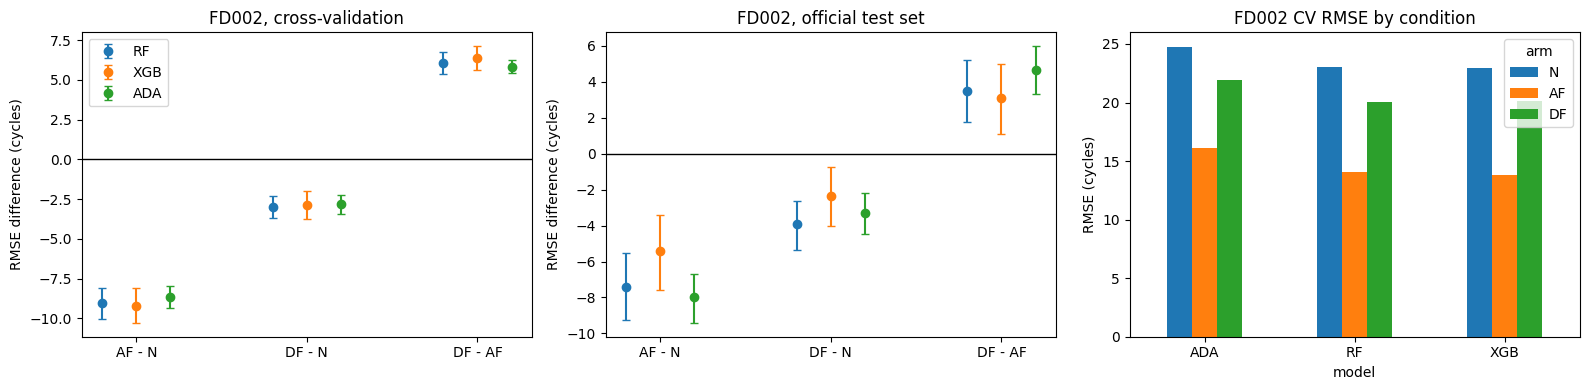

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (title, pre) in zip(axes[:2], [("FD002, cross-validation", "cv"), ("FD002, official test set", "test")]):
    for k, m in enumerate(MODELS):
        r = H[(H.dataset == "FD002") & (H.model == m)].set_index("contrast").reindex([f"{a} - {b}" for a, b in CONTRASTS])
        ax.errorbar(np.arange(3) + (k - 1) * 0.2, r[f"{pre}_delta"], yerr=[r[f"{pre}_delta"] - r[f"{pre}_lo"], r[f"{pre}_hi"] - r[f"{pre}_delta"]], fmt="o", capsize=3, label=m)
    ax.axhline(0, color="k", lw=1); ax.set_xticks(range(3)); ax.set_xticklabels([f"{a} - {b}" for a, b in CONTRASTS]); ax.set_title(title); ax.set_ylabel("RMSE difference (cycles)")
axes[0].legend()
P = T1.pivot_table(index=["dataset", "model"], columns="arm", values="mean")[ARMS]
P.loc["FD002"].plot.bar(ax=axes[2], rot=0); axes[2].set_title("FD002 CV RMSE by condition"); axes[2].set_ylabel("RMSE (cycles)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/q2_fig_effects.png", dpi=120); plt.show()

## 10. Reload one saved model and check it reproduces the test predictions

In [21]:
files = sorted(f for f in os.listdir(MODEL_DIR) if f.endswith((".pth", ".pkl")))
print(len(files), "model files:", files[:4], "...")
ok = 0
for ds, arm, m in [("FD002", "AF", "XGB"), ("FD002", "DF", "RF"), ("FD001", "N", "ADA")]:
    b = load_obj(f"{MODEL_DIR}/{ds}_{arm}_{m}_L{L}{EXT}")
    pred = qc.predict_from_bundle(b, DATA[ds]["test"], RUL_CAP)
    ref = tp[(tp.dataset == ds) & (tp.arm == arm) & (tp.model == m)].set_index("unit").pred
    assert np.allclose([pred[u] for u in ref.index], ref.values, atol=1e-6); ok += 1
print(f"OK  {ok} saved models reloaded from disk and reproduced the stored test predictions")

18 model files: ['FD001_AF_ADA_L50.pth', 'FD001_AF_RF_L50.pth', 'FD001_AF_XGB_L50.pth', 'FD001_DF_ADA_L50.pth'] ...
OK  3 saved models reloaded from disk and reproduced the stored test predictions


## 11. Zip the models and results

In [22]:
README = f'''Q2 models and results
Each model file is a dictionary with: model (fitted estimator), arm (N / AF / DF), L, sensors, settings, norm1 and normk (scaling and condition-cluster state).
Files are {EXT} ({"written with torch.save" if USE_TORCH else "written with joblib: PyTorch was not installed"}). They are NOT neural-network weights; they are fitted Random Forest / XGBoost / AdaBoost objects.

Load and predict (q2_core.py must be on the Python path):
    import torch, pandas as pd, q2_core as qc
    b = torch.load("q2_models/FD002_AF_XGB_L{L}{EXT}", weights_only=False)      # use joblib.load for .pkl
    test = pd.read_csv("test_FD002.csv")                                       # raw readings: unit_id, cycle, settings, sensors
    preds = qc.predict_from_bundle(b, test)                                    # {{unit_id: predicted RUL}}  (capped at {RUL_CAP})
'''
open(f"{OUT_DIR}/README_q2.txt", "w").write(README)
stage = f"{OUT_DIR}/q2_zip_stage"; shutil.rmtree(stage, ignore_errors=True); os.makedirs(stage)
shutil.copytree(MODEL_DIR, f"{stage}/q2_models"); shutil.copy("q2_core.py", stage); shutil.copy(f"{OUT_DIR}/README_q2.txt", stage)
for f in os.listdir(OUT_DIR):
    if f.startswith("q2_") and f.endswith((".csv", ".csv.gz", ".png")): shutil.copy(f"{OUT_DIR}/{f}", stage)
zip_path = shutil.make_archive(f"{OUT_DIR}/q2_models_and_results", "zip", stage)
print("zip:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")

zip: /kaggle/working/q2_models_and_results.zip (30.9 MB)
